# Análise Percentual da Completude dos Recortes QRS por Derivação

Este notebook apresenta a distribuição das situações de extração dos complexos QRS nas **12 derivações** da PTB-XL. Para cada derivação, a porcentagem é calculada em relação ao **total de registros avaliados naquela derivação**:

$$\text{Percentual (\%)} = \frac{\text{Quantidade na situação}}{\text{Total da derivação}} \times 100$$

As cinco situações são **COMPLETA**, **DERIVAÇÃO AUSENTE**, **PARCIAL**, **SEM QRS DETECTADO** e **SEM RECORTES VÁLIDOS**. A classificação *COMPLETA* se refere aos candidatos detectados pelo algoritmo, não à validação clínica de todos os batimentos reais.

**Entrada:** use o CSV `resumo_completude_derivacoes.csv` ou `relatorio_completude_qrs.csv` criado anteriormente. Também é aceito um arquivo Excel `.xlsx` com a mesma tabela. Nenhum valor é inventado: todos os gráficos são calculados a partir do arquivo selecionado.

## 1. Configuração e carregamento dos dados

In [45]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DERIVACOES = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
SITUACOES = ['COMPLETA', 'DERIVAÇÃO AUSENTE', 'PARCIAL', 'SEM QRS DETECTADO', 'SEM RECORTES VÁLIDOS']

# Ajuste para o caminho real do arquivo, se necessário.
# Exemplo Windows: Path(r'C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Recortes-QRS\resumo_completude_derivacoes.csv')
ARQUIVO = Path('Recortes-QRS/resumo_completude_derivacoes.csv')
PASTA_SAIDA = Path('graficos_completude_qrs')
PASTA_SAIDA.mkdir(parents=True, exist_ok=True)

# As cores representam sempre a mesma situação nos gráficos.
CORES = {
    'COMPLETA': '#24734a',
    'DERIVAÇÃO AUSENTE': '#7b7b7b',
    'PARCIAL': '#edaa3b',
    'SEM QRS DETECTADO': '#b54b48',
    'SEM RECORTES VÁLIDOS': '#7355a5',
}


In [46]:
if not ARQUIVO.exists():
    raise FileNotFoundError(
        f'Arquivo não encontrado: {ARQUIVO.resolve()}\n'
        'Altere ARQUIVO para apontar para o CSV ou Excel existente.'
    )

def ler_tabela(caminho):
    if caminho.suffix.lower() in ('.xlsx', '.xls'):
        return pd.read_excel(caminho)
    return pd.read_csv(caminho, encoding='utf-8-sig')

def preparar_contagens(df):
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    if 'derivacao' not in df.columns:
        # Aceita CSV exportado com índice de derivação sem nome.
        if df.columns[0].startswith('Unnamed:'):
            df = df.rename(columns={df.columns[0]: 'derivacao'})
        else:
            raise ValueError('Coluna derivacao não encontrada.')
    df['derivacao'] = df['derivacao'].astype(str).str.strip()
    if 'situacao' in df.columns:
        # Relatório individual: uma linha por ECG e derivação.
        df['situacao'] = df['situacao'].astype(str).str.strip().str.upper()
        cont = pd.crosstab(df['derivacao'], df['situacao'])
    else:
        # Resumo agregado: uma linha por derivação e uma coluna por situação.
        cont = df.set_index('derivacao')
        cont.columns = [str(c).strip().upper() for c in cont.columns]
        cont = cont.apply(pd.to_numeric, errors='coerce').fillna(0)
        cont = cont.groupby(level=0).sum()
    extras = sorted(set(cont.columns) - set(SITUACOES))
    if extras:
        raise ValueError(f'Situações não reconhecidas: {extras}. Revise a entrada antes de calcular os percentuais.')
    cont = cont.reindex(index=DERIVACOES, columns=SITUACOES, fill_value=0).astype(int)
    return cont

entrada = ler_tabela(ARQUIVO)
contagens = preparar_contagens(entrada)
totais = contagens.sum(axis=1)
percentuais = contagens.div(totais.replace(0, np.nan), axis=0).mul(100).fillna(0)

print('Arquivo:', ARQUIVO.resolve())
print('Total por derivação (denominador dos percentuais):')
display(totais.rename('total_registros').to_frame())
if (totais == 0).any():
    print('ATENÇÃO: derivações com total zero serão exibidas como sem dados, não como 0% de completude.')
if totais[totais.gt(0)].nunique() > 1:
    print('ATENÇÃO: os totais variam entre derivações. Confira se todas foram avaliadas sobre o mesmo conjunto de ECGs.')


Arquivo: C:\Users\Matheus\Documents\Detctor-automatizado-QRS\Recortes-QRS\resumo_completude_derivacoes.csv
Total por derivação (denominador dos percentuais):


,total_registros
derivacao,
I,36554
II,36554
III,36554
aVR,36554
aVL,36554
aVF,36554
V1,36554
V2,36554
V3,36554


## 2. Tabela consolidada — quantidade e percentual por derivação

In [47]:
tabela = pd.DataFrame(index=DERIVACOES)
tabela.index.name = 'derivacao'
tabela['TOTAL'] = totais
for situacao in SITUACOES:
    tabela[f'{situacao} (n)'] = contagens[situacao]
    tabela[f'{situacao} (%)'] = percentuais[situacao].round(2)
display(tabela)
tabela.to_csv(PASTA_SAIDA / 'tabela_completude_por_derivacao.csv', encoding='utf-8-sig')

,TOTAL,COMPLETA (n),COMPLETA (%),DERIVAÇÃO AUSENTE (n),DERIVAÇÃO AUSENTE (%),PARCIAL (n),PARCIAL (%),SEM QRS DETECTADO (n),SEM QRS DETECTADO (%),SEM RECORTES VÁLIDOS (n),SEM RECORTES VÁLIDOS (%)
derivacao,,,,,,,,,,,
I,36554,28403,77.70,0,0.0,8150,22.30,0,0.00,1,0.00
II,36554,28505,77.98,0,0.0,8049,22.02,0,0.00,0,0.00
III,36554,28376,77.63,0,0.0,8177,22.37,0,0.00,1,0.00
aVR,36554,0,0.00,36554,100.0,0,0.00,0,0.00,0,0.00
aVL,36554,0,0.00,36554,100.0,0,0.00,0,0.00,0,0.00
aVF,36554,0,0.00,36554,100.0,0,0.00,0,0.00,0,0.00
V1,36554,28475,77.90,0,0.0,8079,22.10,0,0.00,0,0.00
V2,36554,28506,77.98,0,0.0,8048,22.02,0,0.00,0,0.00
V3,36554,28440,77.80,0,0.0,8110,22.19,0,0.00,4,0.01


## 3. Gráfico geral — distribuição percentual das 12 derivações

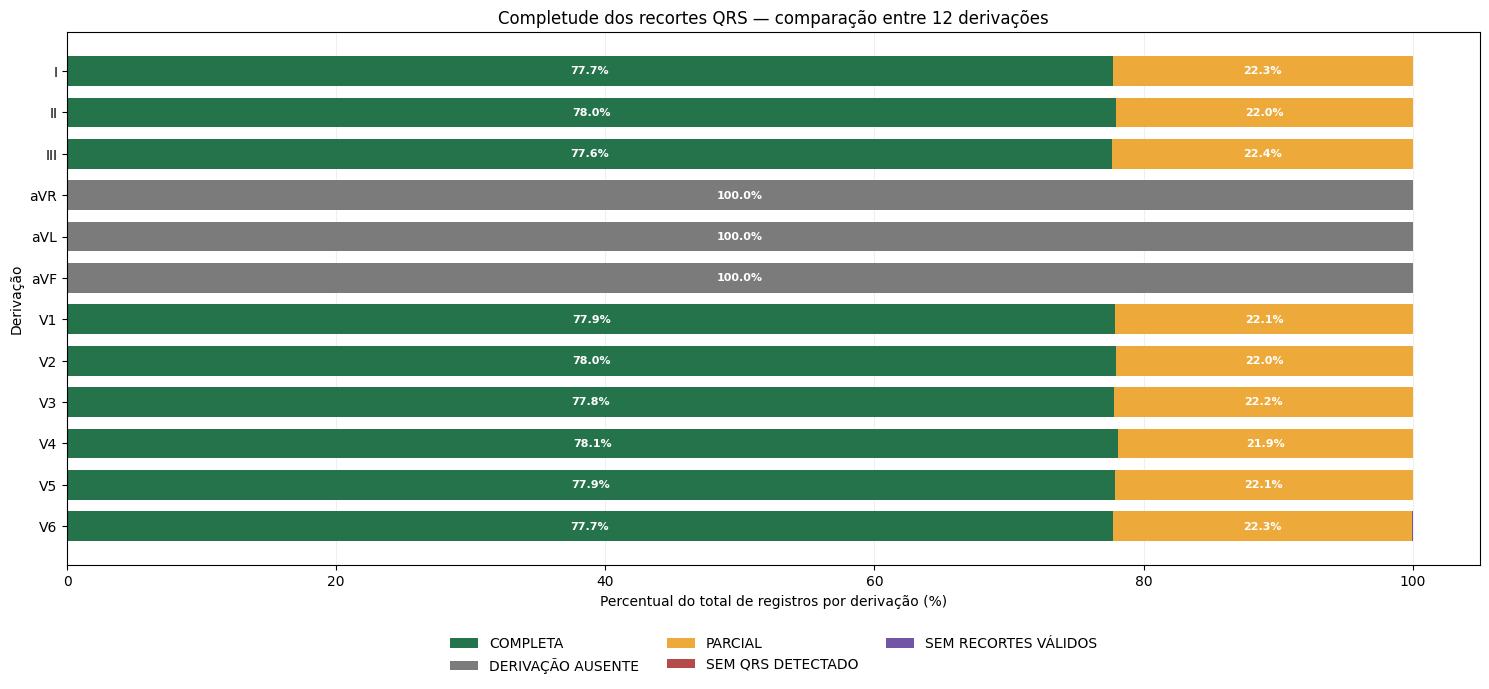

In [48]:
fig, ax = plt.subplots(figsize=(15, 7))
acumulado = np.zeros(len(DERIVACOES))
for situacao in SITUACOES:
    valores = percentuais[situacao].to_numpy()
    ax.barh(DERIVACOES, valores, left=acumulado, label=situacao, color=CORES[situacao], height=0.72)
    for i, (valor, base) in enumerate(zip(valores, acumulado)):
        if valor >= 6:
            ax.text(base + valor / 2, i, f'{valor:.1f}%', ha='center', va='center', fontsize=8, color='white', fontweight='bold')
    acumulado += valores
ax.set_xlim(0, 105)
ax.set_xlabel('Percentual do total de registros por derivação (%)')
ax.set_ylabel('Derivação')
ax.set_title('Completude dos recortes QRS — comparação entre 12 derivações')
ax.invert_yaxis()
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.11), ncol=3, frameon=False)
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(PASTA_SAIDA / 'visao_geral_12_derivacoes.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Função para gráficos individuais

In [49]:
def grafico_derivacao(derivacao):
    total = int(totais.loc[derivacao])
    qtd = contagens.loc[derivacao]
    pct = percentuais.loc[derivacao]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    barras = ax.barh(SITUACOES, pct.values, color=[CORES[s] for s in SITUACOES], height=0.62)
    ax.invert_yaxis()
    ax.set_xlim(0, 116)
    ax.set_xlabel('Percentual em relação ao total da derivação (%)')
    ax.set_title(f'Derivação {derivacao} — distribuição das situações QRS (N = {total:,})'.replace(',', '.'))
    for barra, situacao in zip(barras, SITUACOES):
        v = float(pct[situacao]); n = int(qtd[situacao])
        ax.text(v + 1, barra.get_y() + barra.get_height() / 2,
                f'{v:.2f}%  (n={n:,})'.replace(',', '.'), va='center', fontsize=10)
    if total == 0:
        ax.text(0.5, 0.5, 'SEM DADOS PARA ESTA DERIVAÇÃO', transform=ax.transAxes,
                ha='center', va='center', fontsize=13, fontweight='bold')
    ax.grid(axis='x', alpha=0.18)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(PASTA_SAIDA / f'completude_{derivacao}.png', dpi=180, bbox_inches='tight')
    plt.show()
    return pd.DataFrame({'Quantidade': qtd, 'Percentual (%)': pct.round(2)})


## Gráficos da I

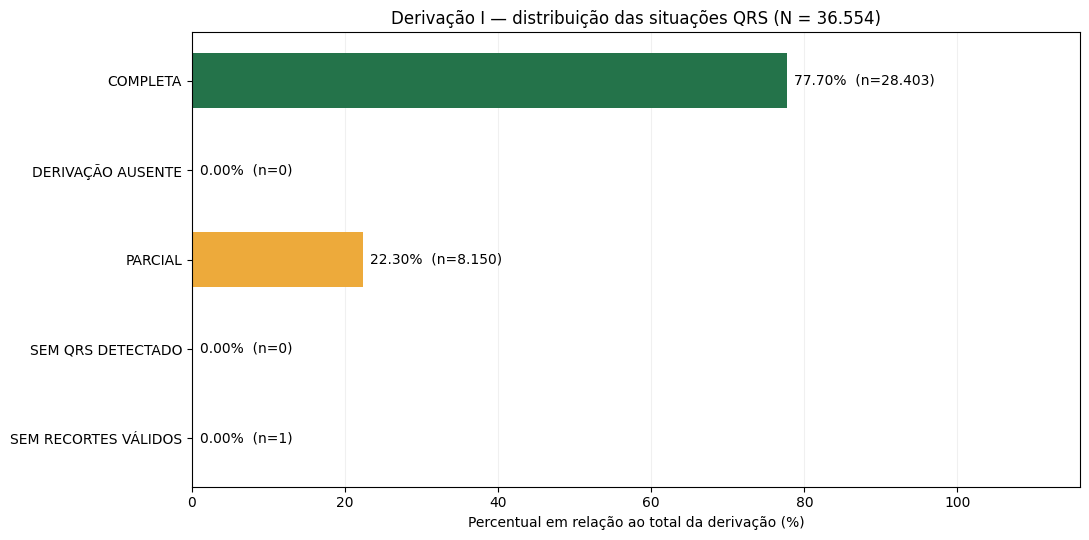

,Quantidade,Percentual (%)
COMPLETA,28403,77.7
DERIVAÇÃO AUSENTE,0,0.0
PARCIAL,8150,22.3
SEM QRS DETECTADO,0,0.0
SEM RECORTES VÁLIDOS,1,0.0


In [50]:
display(grafico_derivacao('I'))

## Gráficos da II

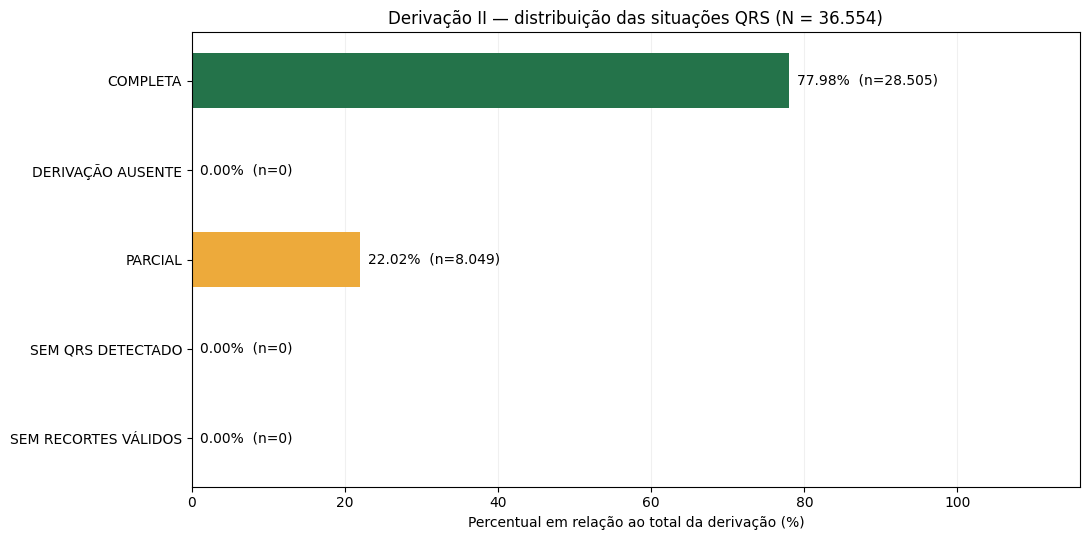

,Quantidade,Percentual (%)
COMPLETA,28505,77.98
DERIVAÇÃO AUSENTE,0,0.00
PARCIAL,8049,22.02
SEM QRS DETECTADO,0,0.00
SEM RECORTES VÁLIDOS,0,0.00


In [51]:
display(grafico_derivacao('II'))

## Gráficos da III

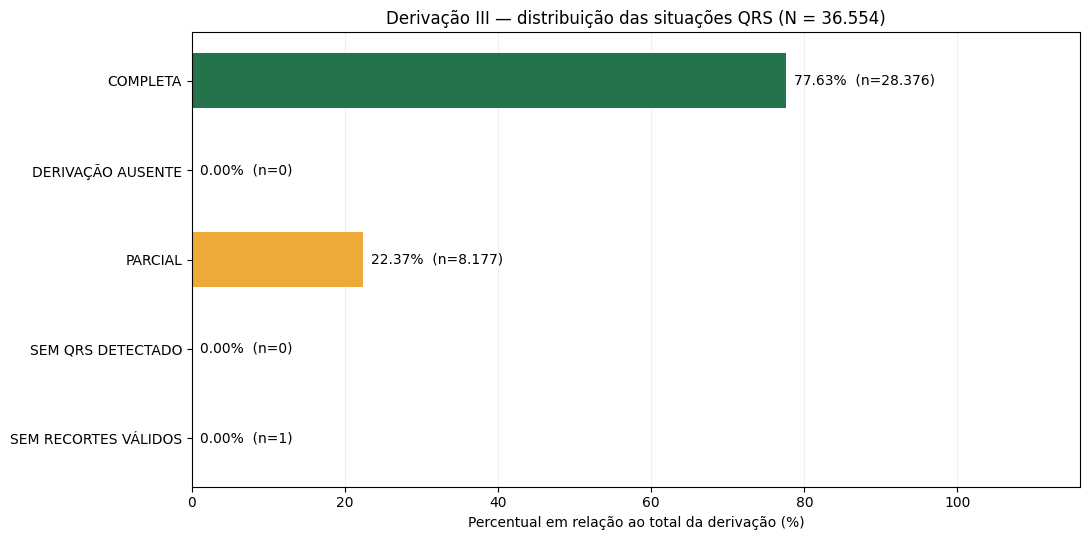

,Quantidade,Percentual (%)
COMPLETA,28376,77.63
DERIVAÇÃO AUSENTE,0,0.00
PARCIAL,8177,22.37
SEM QRS DETECTADO,0,0.00
SEM RECORTES VÁLIDOS,1,0.00


In [52]:
display(grafico_derivacao('III'))

## Gráficos da aVR

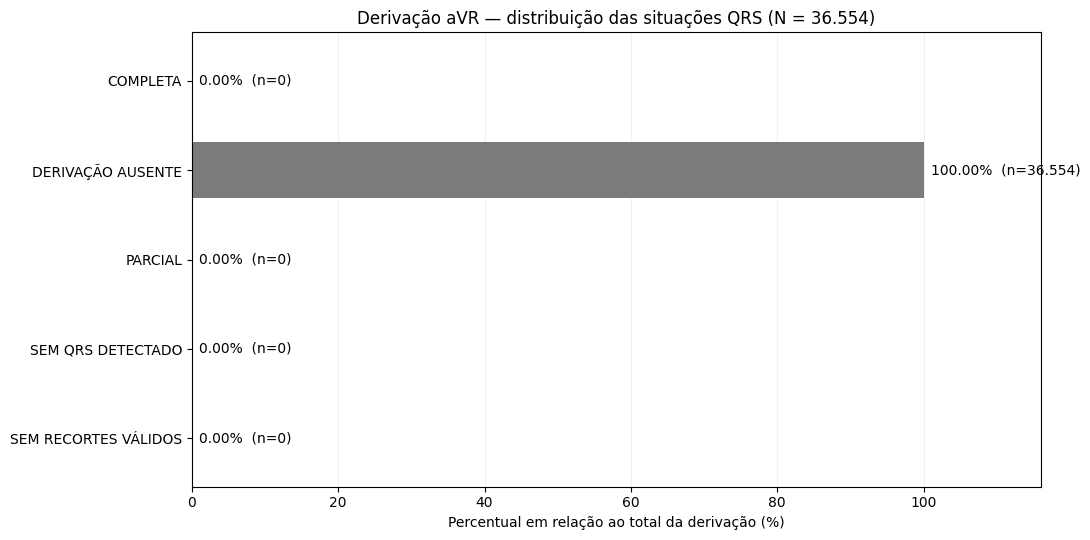

,Quantidade,Percentual (%)
COMPLETA,0,0.0
DERIVAÇÃO AUSENTE,36554,100.0
PARCIAL,0,0.0
SEM QRS DETECTADO,0,0.0
SEM RECORTES VÁLIDOS,0,0.0


In [53]:
display(grafico_derivacao('aVR'))

## Gráficos da aVL

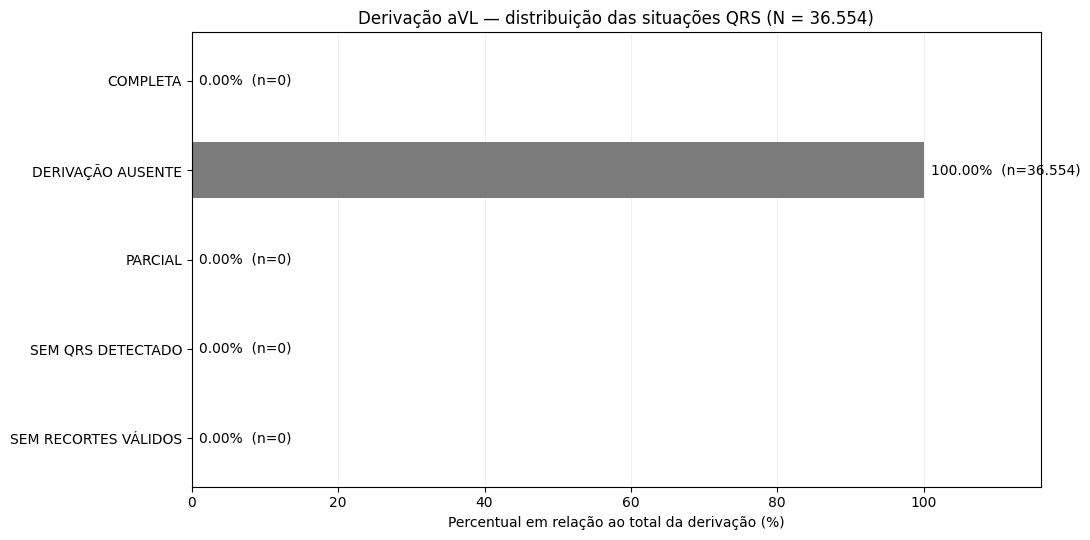

,Quantidade,Percentual (%)
COMPLETA,0,0.0
DERIVAÇÃO AUSENTE,36554,100.0
PARCIAL,0,0.0
SEM QRS DETECTADO,0,0.0
SEM RECORTES VÁLIDOS,0,0.0


In [54]:
display(grafico_derivacao('aVL'))

## Gráficos da aVF

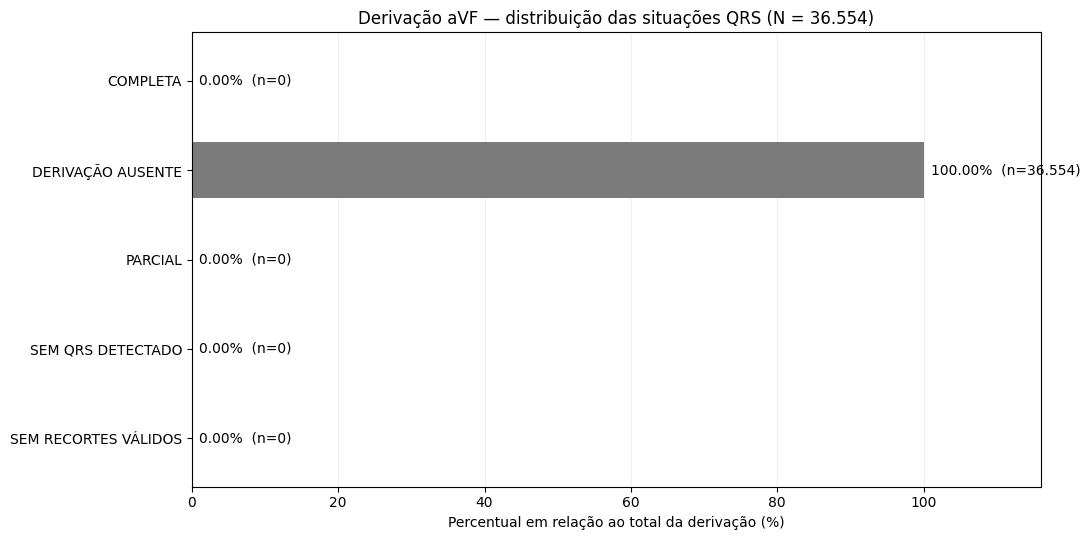

,Quantidade,Percentual (%)
COMPLETA,0,0.0
DERIVAÇÃO AUSENTE,36554,100.0
PARCIAL,0,0.0
SEM QRS DETECTADO,0,0.0
SEM RECORTES VÁLIDOS,0,0.0


In [55]:
display(grafico_derivacao('aVF'))

## Gráficos da V1

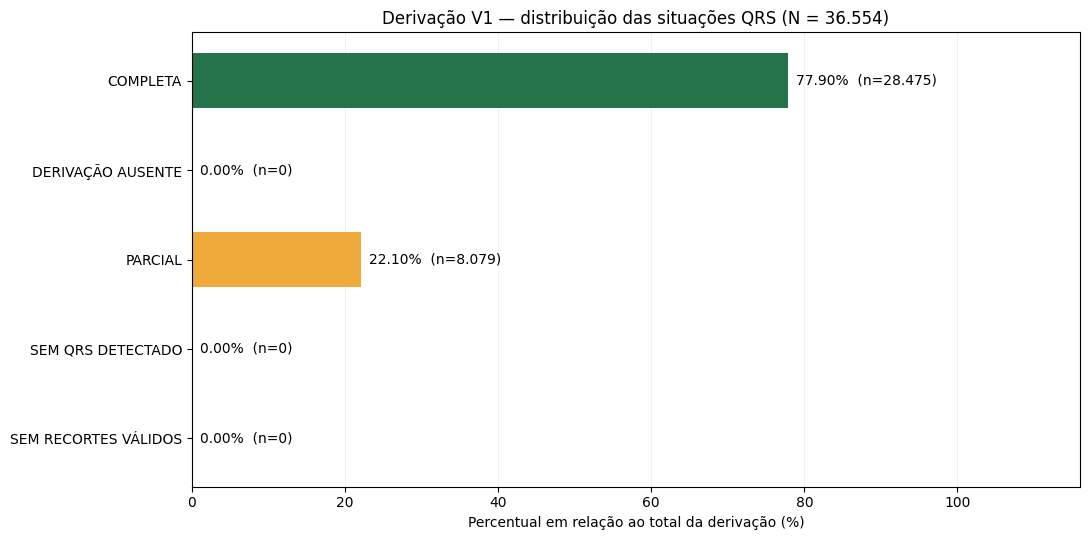

,Quantidade,Percentual (%)
COMPLETA,28475,77.9
DERIVAÇÃO AUSENTE,0,0.0
PARCIAL,8079,22.1
SEM QRS DETECTADO,0,0.0
SEM RECORTES VÁLIDOS,0,0.0


In [56]:
display(grafico_derivacao('V1'))

## Gráficos da V2

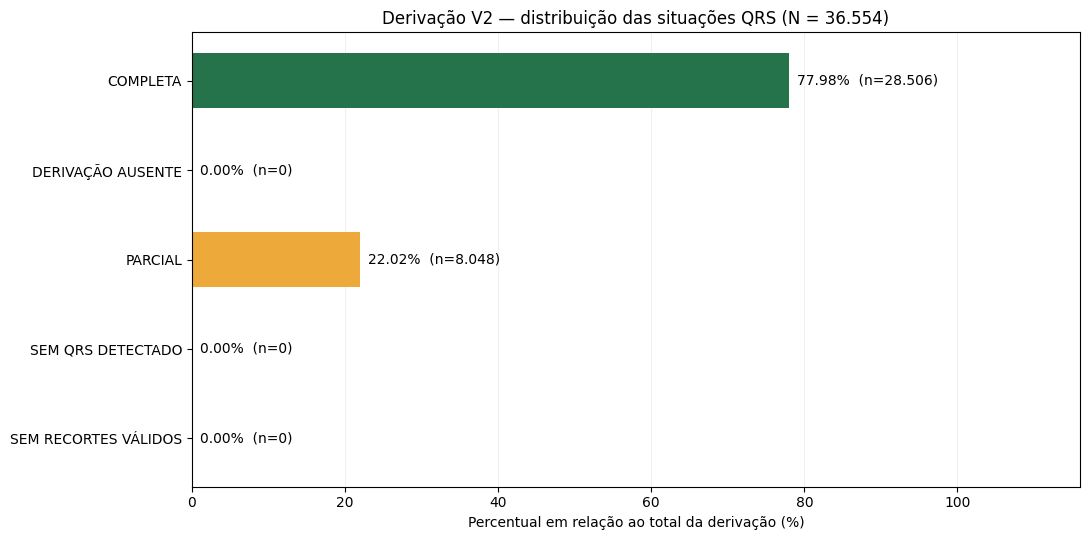

,Quantidade,Percentual (%)
COMPLETA,28506,77.98
DERIVAÇÃO AUSENTE,0,0.00
PARCIAL,8048,22.02
SEM QRS DETECTADO,0,0.00
SEM RECORTES VÁLIDOS,0,0.00


In [57]:
display(grafico_derivacao('V2'))

## Gráficos da V3

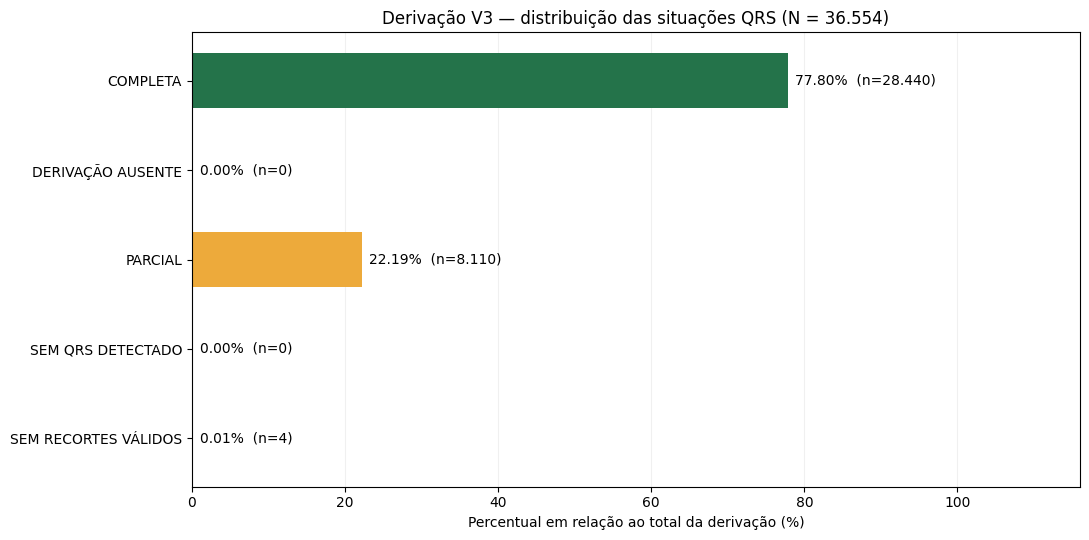

,Quantidade,Percentual (%)
COMPLETA,28440,77.80
DERIVAÇÃO AUSENTE,0,0.00
PARCIAL,8110,22.19
SEM QRS DETECTADO,0,0.00
SEM RECORTES VÁLIDOS,4,0.01


In [58]:
display(grafico_derivacao('V3'))

## Gráficos da V4

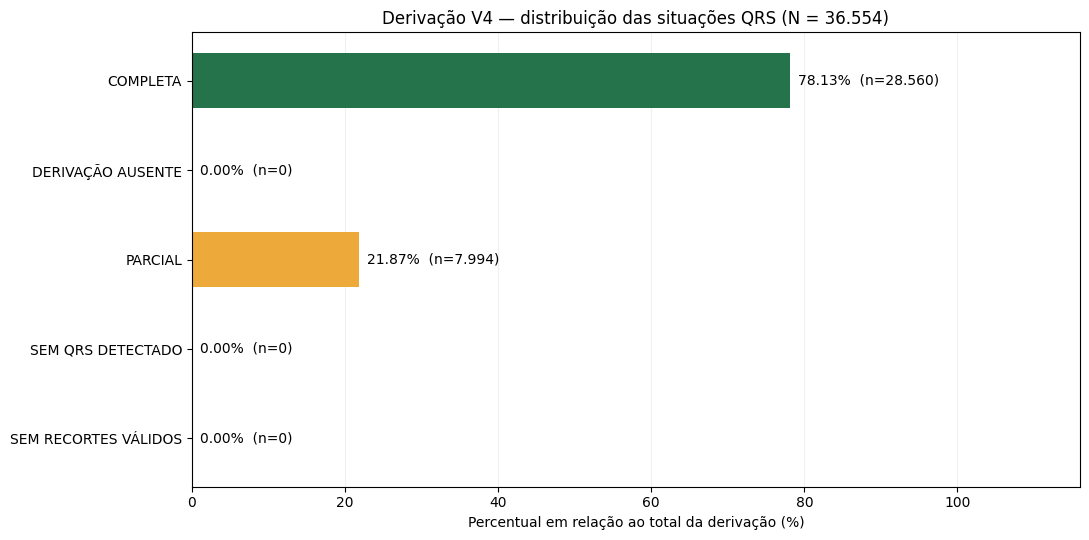

,Quantidade,Percentual (%)
COMPLETA,28560,78.13
DERIVAÇÃO AUSENTE,0,0.00
PARCIAL,7994,21.87
SEM QRS DETECTADO,0,0.00
SEM RECORTES VÁLIDOS,0,0.00


In [59]:
display(grafico_derivacao('V4'))

## Gráficos da V5

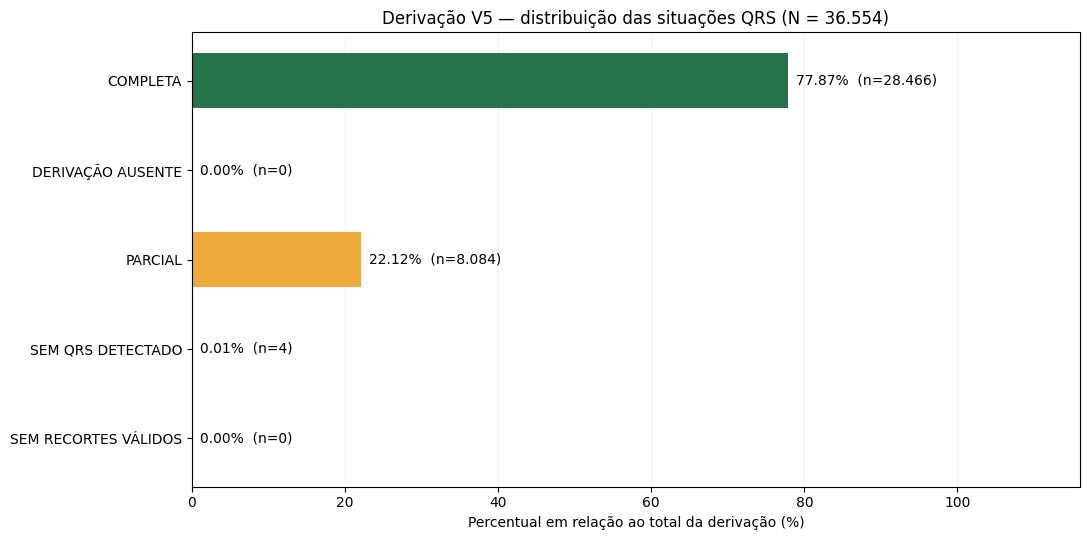

,Quantidade,Percentual (%)
COMPLETA,28466,77.87
DERIVAÇÃO AUSENTE,0,0.00
PARCIAL,8084,22.12
SEM QRS DETECTADO,4,0.01
SEM RECORTES VÁLIDOS,0,0.00


In [60]:
display(grafico_derivacao('V5'))

## Gráficos da V6

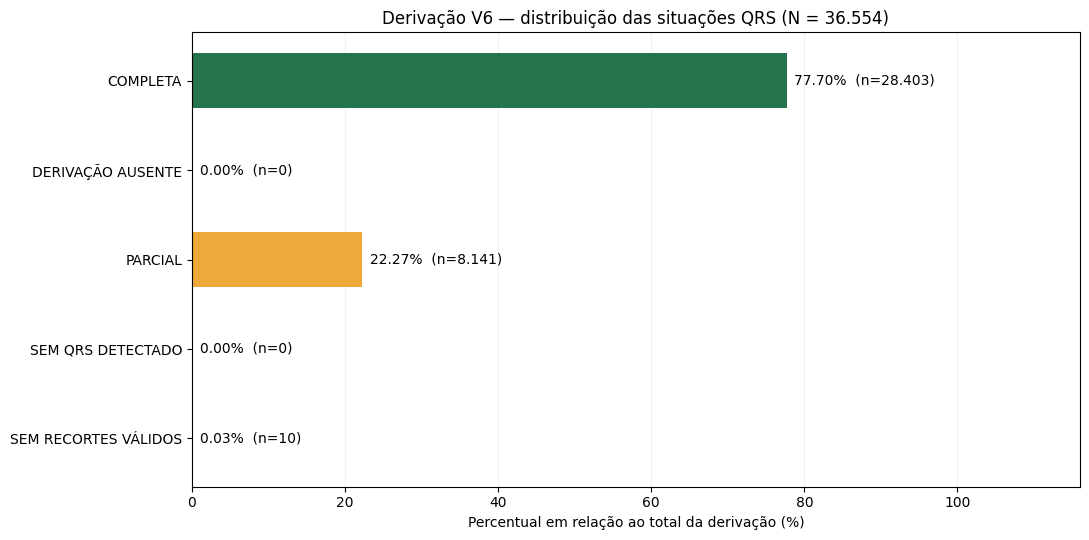

,Quantidade,Percentual (%)
COMPLETA,28403,77.70
DERIVAÇÃO AUSENTE,0,0.00
PARCIAL,8141,22.27
SEM QRS DETECTADO,0,0.00
SEM RECORTES VÁLIDOS,10,0.03


In [61]:
display(grafico_derivacao('V6'))

## 5. Interpretação e limitações

- O denominador é o **total de registros daquela derivação** (soma das cinco situações). A soma dos percentuais deve ser aproximadamente 100%, exceto em derivações sem dados.
- **COMPLETA** indica que todos os candidatos QRS identificados para o registro/derivação foram considerados válidos segundo a regra de classificação empregada; não comprova que todos os batimentos cardíacos reais foram encontrados.
- **PARCIAL** indica que pelo menos um candidato teve recorte válido, mas nem todos.
- A integridade de cada CSV (amostras faltantes, duplicadas ou valores ausentes) exige uma verificação adicional; este notebook resume as **situações previamente classificadas**.
- As contagens são de **registros por derivação**, não de batimentos, desde que o arquivo de entrada tenha uma linha por ECG/derivação ou seja o resumo correspondente.
- Se a extração original descartou registros por problema de identificação do arquivo, eles **não aparecem automaticamente** nestes percentuais. A cobertura total da PTB-XL deve ser auditada separadamente.

As figuras e a tabela consolidada são salvas na pasta `graficos_completude_qrs`.